# Week 5 – Task 5: Mini Project – Handwritten Digit Recognition with a Neural Network

## 1. Problem Statement
Automatically recognise handwritten digits (0–9) from images. Applications include postal-code reading, bank-cheque processing and form digitisation. This is a **10-class image classification** problem solved with a fully-connected ANN.

## 2. Dataset Description
The scikit-learn **Digits** dataset (UCI Optical Recognition of Handwritten Digits): 1,797 grayscale images of size 8×8 pixels (64 features, values 0–16), balanced across 10 classes. It is bundled with scikit-learn so it runs offline; the same code works for MNIST (28×28) by changing the input size.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
np.random.seed(7); tf.random.set_seed(7)
tf.config.experimental.enable_op_determinism()

digits = load_digits()
X, y = digits.data, digits.target
print('Images:', X.shape, '| Labels:', y.shape)
print('Class counts:', np.bincount(y))

I0000 00:00:1793615987.349918    1843 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793615987.431144    1843 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1793615989.228978    1843 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Images: (1797, 64) | Labels: (1797,)
Class counts: [178 182 177 183 181 182 181 179 174 180]


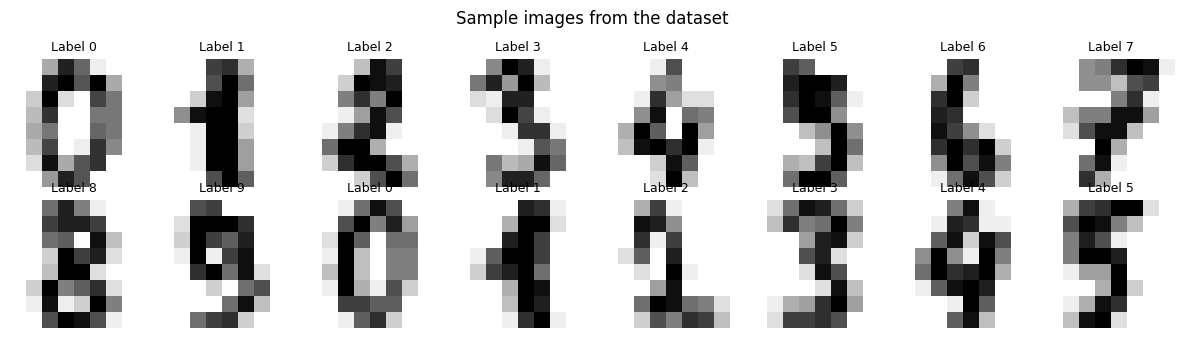

In [2]:
fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
for ax, img, lab in zip(axes.ravel(), digits.images, digits.target):
    ax.imshow(img, cmap='gray_r'); ax.set_title(f'Label {lab}', fontsize=9); ax.axis('off')
plt.suptitle('Sample images from the dataset'); plt.tight_layout(); plt.savefig('digits_samples.png', dpi=150); plt.show()

## 3. Data Preprocessing & Train/Test Split
- Normalise pixel values to the range 0–1 (divide by 16).
- One integer label per image (used with `sparse_categorical_crossentropy`).
- 80/20 stratified split.

In [3]:
X = X / 16.0
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=7, stratify=y)
print('Train:', X_train.shape, 'Test:', X_test.shape, '| pixel range:', X.min(), '-', X.max())

Train: (1437, 64) Test: (360, 64) | pixel range: 0.0 - 1.0


## 4. Neural Network Architecture
64 inputs → Dense(128, ReLU) → Dropout(0.2) → Dense(64, ReLU) → Dense(10, Softmax)

In [4]:
model = keras.Sequential([
    layers.Input(shape=(64,)),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
], name='digit_ann')
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "digit_ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,226 (67.29 KB)

 Trainable params: 17,226 (67.29 KB)

 Non-trainable params: 0 (0.00 B)

## 5. Model Training

In [5]:
history = model.fit(X_train, y_train, epochs=40, batch_size=32, validation_split=0.2, verbose=2)

Epoch 1/40


E0000 00:00:1793615991.353517    1843 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


36/36 - 2s - 58ms/step - accuracy: 0.4517 - loss: 1.9897 - val_accuracy: 0.8090 - val_loss: 1.5139


Epoch 2/40


36/36 - 0s - 9ms/step - accuracy: 0.7929 - loss: 1.1194 - val_accuracy: 0.8924 - val_loss: 0.7340


Epoch 3/40


... (71 outputs left out)

Epoch 39/40


36/36 - 0s - 9ms/step - accuracy: 1.0000 - loss: 0.0186 - val_accuracy: 0.9722 - val_loss: 0.0946


Epoch 40/40


36/36 - 0s - 8ms/step - accuracy: 0.9965 - loss: 0.0194 - val_accuracy: 0.9757 - val_loss: 0.0851


## 6. Accuracy & Loss Graphs

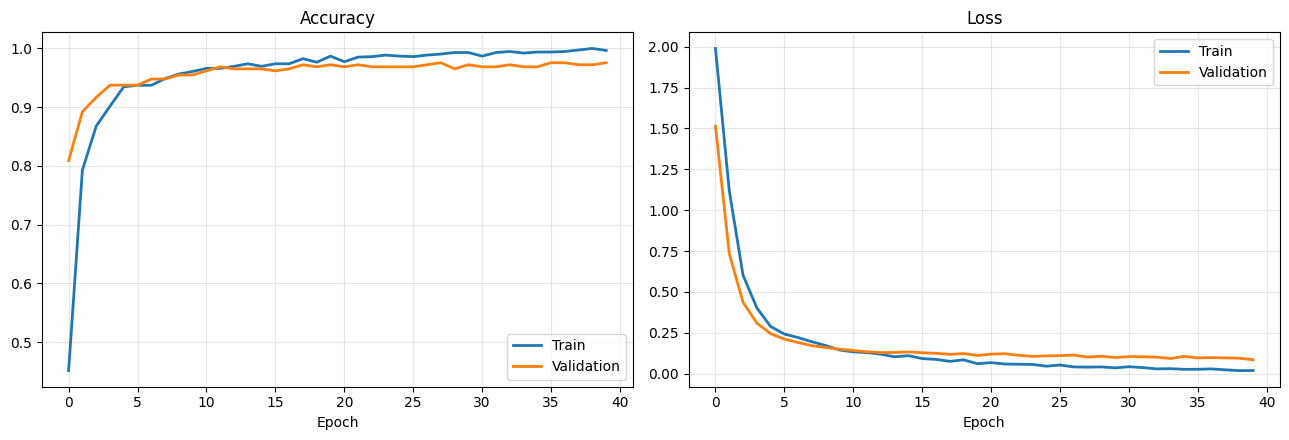

In [6]:
h = history.history
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(h['accuracy'], label='Train', lw=2); ax[0].plot(h['val_accuracy'], label='Validation', lw=2)
ax[0].set_title('Accuracy'); ax[0].set_xlabel('Epoch'); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(h['loss'], label='Train', lw=2); ax[1].plot(h['val_loss'], label='Validation', lw=2)
ax[1].set_title('Loss'); ax[1].set_xlabel('Epoch'); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig('mini_curves.png', dpi=150); plt.show()

## 7. Model Evaluation

In [7]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f'Test loss: {test_loss:.4f} | Test accuracy: {test_acc*100:.2f}%')
y_pred = model.predict(X_test, verbose=0).argmax(axis=1)
print(classification_report(y_test, y_pred))

E0000 00:00:1793616006.373772    1843 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


Test loss: 0.0640 | Test accuracy: 97.50%


              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.97      1.00      0.99        37
           2       1.00      1.00      1.00        35
           3       0.97      0.95      0.96        37
           4       0.97      1.00      0.99        36
           5       0.94      0.94      0.94        36
           6       1.00      0.97      0.99        36
           7       1.00      1.00      1.00        36
           8       0.92      0.97      0.94        35
           9       0.97      0.92      0.94        36

    accuracy                           0.97       360
   macro avg       0.98      0.98      0.97       360
weighted avg       0.98      0.97      0.97       360



## 8. Predictions (actual vs predicted)

In [8]:
idx = np.arange(10)
pd.DataFrame({'Actual': y_test[idx], 'Predicted': y_pred[idx],
              'Correct?': np.where(y_test[idx]==y_pred[idx],'Yes','No')})

,Actual,Predicted,Correct?
0,9,3,No
1,4,4,Yes
2,6,6,Yes
3,4,4,Yes
4,8,8,Yes
5,4,4,Yes
6,9,5,No
7,9,9,Yes
8,2,2,Yes
9,8,8,Yes


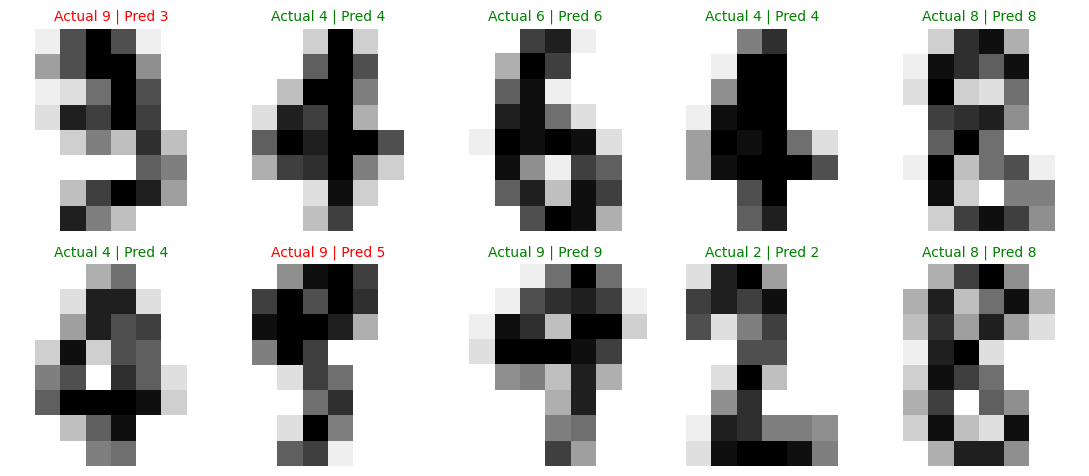

In [9]:
fig, axes = plt.subplots(2, 5, figsize=(11, 5))
for ax, i in zip(axes.ravel(), range(10)):
    ax.imshow(X_test[i].reshape(8,8), cmap='gray_r')
    ok = y_test[i]==y_pred[i]
    ax.set_title(f'Actual {y_test[i]} | Pred {y_pred[i]}', color='green' if ok else 'red', fontsize=10); ax.axis('off')
plt.tight_layout(); plt.savefig('mini_predictions.png', dpi=150); plt.show()

## 9. Confusion Matrix

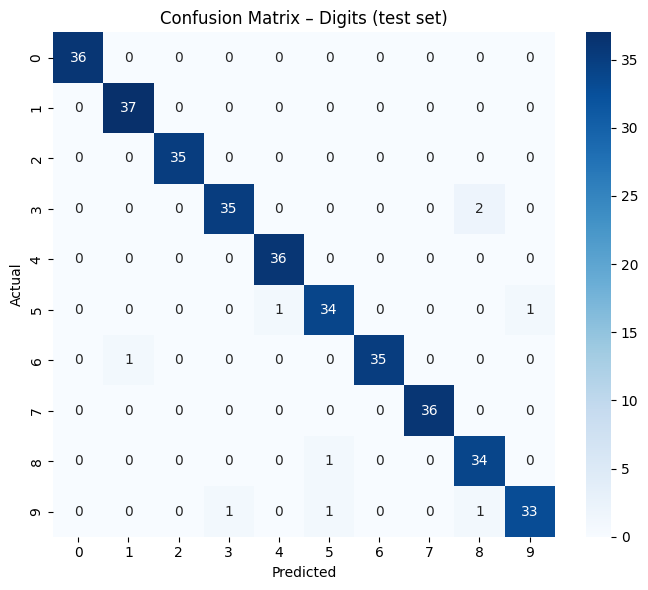

In [10]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Confusion Matrix – Digits (test set)')
plt.tight_layout(); plt.savefig('mini_confusion.png', dpi=150); plt.show()

Misclassified: 9 of 360


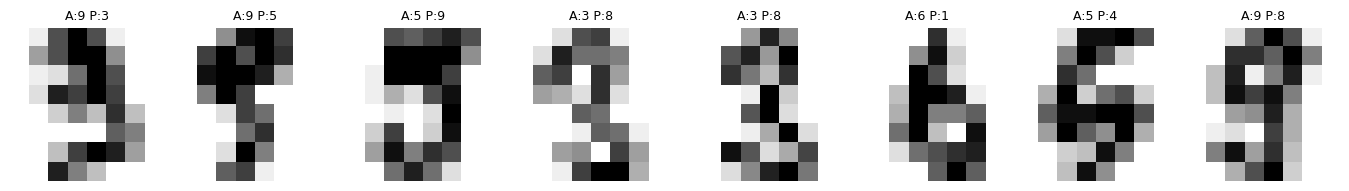

In [11]:
wrong = np.where(y_test != y_pred)[0]
print('Misclassified:', len(wrong), 'of', len(y_test))
if len(wrong):
    n = min(len(wrong), 8)
    fig, axes = plt.subplots(1, n, figsize=(1.7*n, 2.4))
    axes = np.atleast_1d(axes)
    for ax, i in zip(axes, wrong[:n]):
        ax.imshow(X_test[i].reshape(8,8), cmap='gray_r'); ax.set_title(f'A:{y_test[i]} P:{y_pred[i]}', fontsize=9); ax.axis('off')
    plt.tight_layout(); plt.savefig('mini_wrong.png', dpi=150); plt.show()

## 10. Final Conclusion & Report

**Problem.** Recognise handwritten digits (0-9) automatically, as used in postal-code reading and form digitisation.

**Dataset.** The scikit-learn Digits dataset has 1,797 grayscale 8x8 images (64 pixel features) in 10 balanced classes. Pixels were scaled to 0-1 and the data split 80/20 (1,437 train, 360 test, stratified).

**Architecture.** A fully connected network: 64 inputs, Dense(128, ReLU), Dropout(0.2), Dense(64, ReLU) and Dense(10, Softmax). It was compiled with Adam and sparse categorical cross-entropy.

**Training.** The model trained for 40 epochs with batch size 32 and 20% of the training data used for validation. Training accuracy rose from 45.2% to 99.7% and validation accuracy from 80.9% to 97.6%, while validation loss fell from 1.51 to 0.085. The two curves stayed close, so overfitting was mild; Dropout helped.

**Results.** Test accuracy was 97.5% (9 of 360 images misclassified). Most digit classes scored an F1 of 0.96 or higher; digit 8 was weakest, and errors involved visually similar digits such as 9, 3 and 5.

**Limitations.** The images are tiny (8x8) and clean, a dense network ignores the 2-D structure of images, and only one train/test split was used, so the estimate has some variance.

**Future improvements.** Use a Convolutional Neural Network on full-size MNIST, add data augmentation, tune hyperparameters, use cross-validation and EarlyStopping, and deploy the model in a small web app. Overall, the project shows that even a small neural network can learn useful patterns directly from raw pixels, and that careful preprocessing, validation curves and a confusion matrix are what make the results trustworthy. The same workflow can be reused for other classification problems such as medical or student-performance data.